In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy import linalg
import seaborn as sns
from matplotlib import pyplot as plt
import fastplotlib as fpl

%matplotlib inline

wgpu version from git (0.15.3) and __version__ (0.19.3) don't match.
rendercanvas version from git (2.0.0) and __version__ (2.0.1) don't match.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅,AMD Radeon 780M (RADV GFX1103_R1),IntegratedGPU,Vulkan,Mesa 24.2.8
✅ (default),NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
✅,NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
❗ limited,"llvmpipe (LLVM 19.1.0, 256 bits)",CPU,Vulkan,Mesa 24.2.8 (LLVM 19.1.0)
❌,"AMD Radeon 780M (radeonsi, gfx1103_r1, LLVM 19.1.0, DRM 3.59, 6.12.4-200.fc41.x86_64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 24.2.8


pygfx version from git (0.6.0) and __version__ (0.7.0) don't match.
Incompatible version of wgpu:
    Detected 0.15.3.post104+g63d70c0, need >=(0, 19, 0), <(0, 20, 0).
    To update, use e.g. `pip install -U wgpu`.


In [2]:
fpl.select_adapter(fpl.enumerate_adapters()[0])

In [3]:
def generate_data(
        n_timepoints: int,
        n_components: int,
        noise: int,
        n_pixels: int | tuple[int, int],  # n_pixels PER component, if a tuple a random number of pixles within the range is used
        n_pixels_bg = 0,
        firing_prop = 0.05,
        interp_factor: int = 2,
) -> tuple[np.ndarray, np.ndarray]:
    """

    Parameters
    ----------
    n_timepoints: int

    n_components: int

    noise: int

    n_pixels: int, or (min, max) range
        n_pixels PER components, if (min, max) range is given then a random number of pixels within this range
        is used for each component

    n_pixels_bg: int

    interp_factor: int
        interpolation factor

    Returns
    -------
    np.ndarray, np.ndarray
        data [pixels, n_timepoints * interp_factor], truth labels: 1D array 0 is background

    """

    clean = np.zeros((n_components, n_timepoints * interp_factor)) + 0.01
    # print(clean)

    x = 0
    a_decay = 0.7
    a_rise = 5

    (0.01 / 5) * (5 / 0.01) * 5

    b = 0

    n_rise = 0

    spikes = list()

    for i in range(n_components):
        spikes.append((np.random.rand(n_timepoints) < firing_prop).astype(bool))

    for c_ix in range(n_components):
        for i in range(2, n_timepoints):
            if spikes[c_ix][i]:
                a = a_rise
                n_rise = 5
            elif n_rise > 0:
                if clean[c_ix, i - 1] > 1:
                    a = a_decay
                    n_rise = 0
                else:
                    a = a_rise
                    n_rise -= 1
            else:
                a = a_decay
            clean[c_ix, i] = (a * clean[c_ix, i - 1]) + (b * clean[c_ix, i - 2])# + (1 * spikes[c_ix][i])

        x_ = np.arange(0, n_timepoints * interp_factor)
        xp_ = np.linspace(0, n_timepoints * interp_factor, n_timepoints)
        clean[c_ix] = np.interp(x_, xp_, fp=clean[c_ix, :n_timepoints])

    n_timepoints *= interp_factor

    series = list()
    labels = list()

    for i in range(n_components):
        # determine number of pixels for this component
        if isinstance(n_pixels, int):
            _n_pixels_iter = n_pixels
        elif isinstance(n_pixels, tuple):
            _n_pixels_iter = np.random.randint(low=n_pixels[0], high=n_pixels[1])

        for j in range(_n_pixels_iter):
            series.append(clean[i] + np.random.normal(scale=noise, size=n_timepoints))
            labels.append(i + 1)

    # series = np.vstack(series)

    bg_pixels = [np.random.normal(scale=noise, size=n_timepoints) for i in range(n_pixels_bg)]
    series = np.vstack([*series, *bg_pixels])
    labels = np.array([*labels, *[0 for i in range(len(bg_pixels))]])

    return series, labels

In [4]:
n_components = 1

In [205]:
np.random.seed(0)
X, _ = generate_data(
    n_timepoints=250,
    n_components=n_components,
    noise=0.01,
    n_pixels=1,
    n_pixels_bg=0,
    interp_factor=2,
    firing_prop=0.05,
)

In [206]:
X.shape

(1, 500)

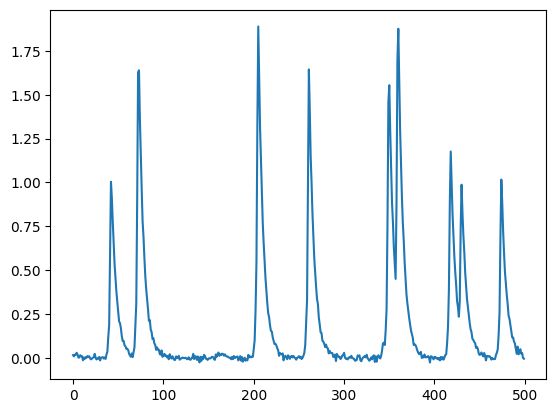

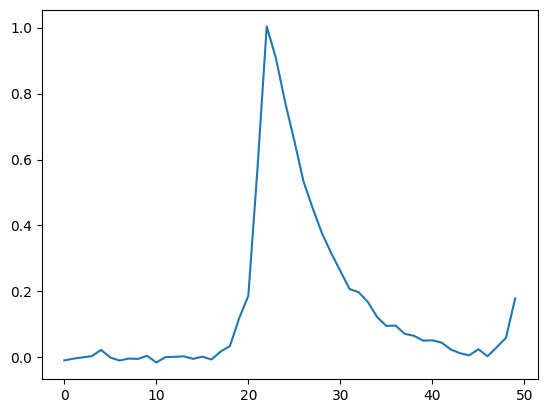

In [207]:
plt.plot(X[0])
# plt.plot(X[1])
plt.show()
plt.plot(X.ravel()[20:70])

In [586]:
lag = 2

H = scipy.linalg.hankel(X[0, :lag * 2], X[0, lag * 2 - 1:])

<Axes: >

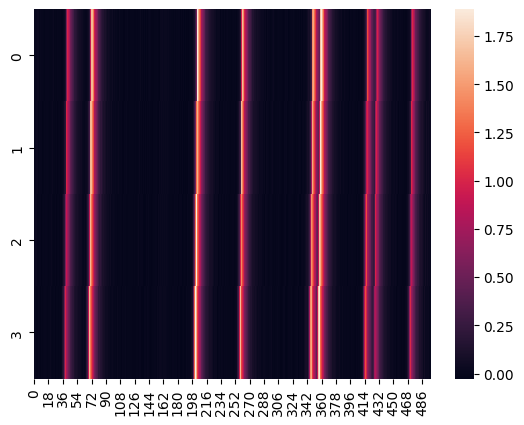

In [587]:
sns.heatmap(H)

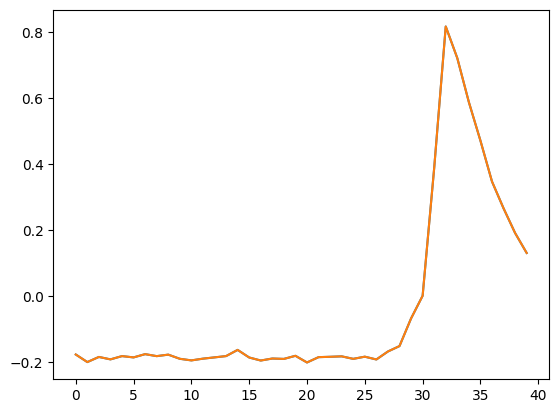

In [608]:
plt.plot(X.ravel()[10:50] - mu0)
plt.plot(H[0, 10:50])

<Axes: >

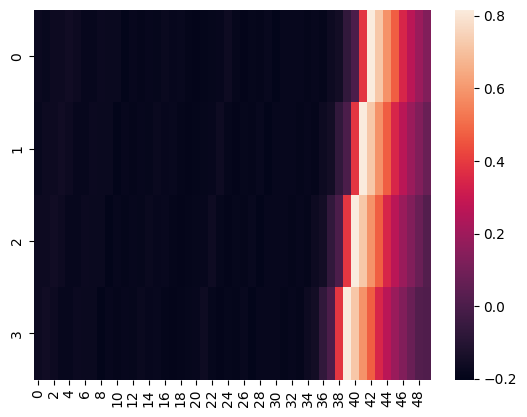

In [603]:
sns.heatmap(H[:, :50])

In [588]:
mu0 = np.mean(H[:2])
mu1 = np.mean(H[2:])

In [589]:
H[:2] -= mu0
H[2:] -= mu1

In [590]:
cov = (H @ H.T) / H.shape[1]

<Axes: >

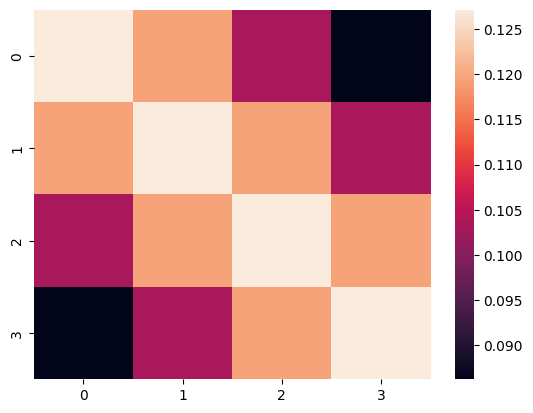

In [591]:
sns.heatmap(cov)

In [592]:
cov

array([[0.12711114, 0.11952247, 0.10326291, 0.08625974],
       [0.11952247, 0.12710318, 0.119521  , 0.10326629],
       [0.10326291, 0.119521  , 0.12710964, 0.11953271],
       [0.08625974, 0.10326629, 0.11953271, 0.12712646]])

In [593]:
past = H[:2]
future = H[2:]

In [594]:
past.shape

(2, 497)

In [595]:
PP = past @ past.T / past.shape[1]
FF = future @ future.T / future.shape[1]
PF = past @ future.T / past.shape[1]

In [596]:
from deeptime.numeric import spd_inv_sqrt

In [597]:
PP_inv_sqrt = linalg.inv(linalg.sqrtm(PP))
FF_inv_sqrt = linalg.inv(linalg.sqrtm(FF))

K_bar = PP_inv_sqrt @ PF @ FF_inv_sqrt

In [598]:
U, S, Vh = np.linalg.svd(K_bar,full_matrices=False)

# mapping data to the left and right sigular vectors
left_vec = PP_inv_sqrt @ U
right_vec = FF_inv_sqrt @ Vh.T

# projection of data onto left and right singular vectors
# proj_left = past.T @ left_vec
# proj_right = future.T @ right_vec

proj_left = left_vec.T @ past
proj_right = right_vec.T @ future

Text(0.5, 1.0, 'right')

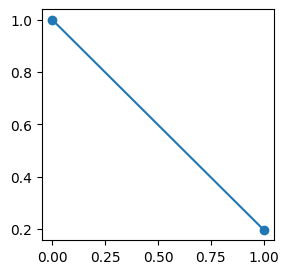

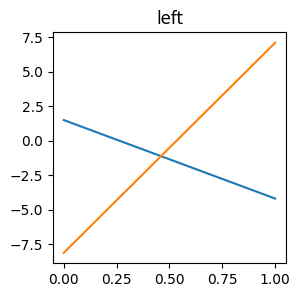

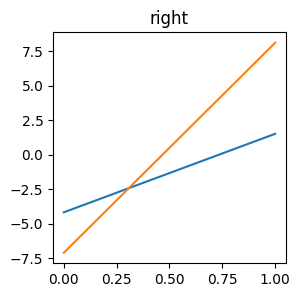

In [599]:
plt.figure(figsize=(3, 3))
plt.plot(S / S.max(),'o-')

plt.figure(figsize=(3, 3))
plt.plot(left_vec)
plt.title("left")

plt.figure(figsize=(3, 3))
plt.plot(right_vec)
plt.title("right")

In [609]:
proj_left.shape

(2, 497)

In [610]:
X.ravel().shape

(500,)

Text(0.5, 1.0, 'proj left, past')

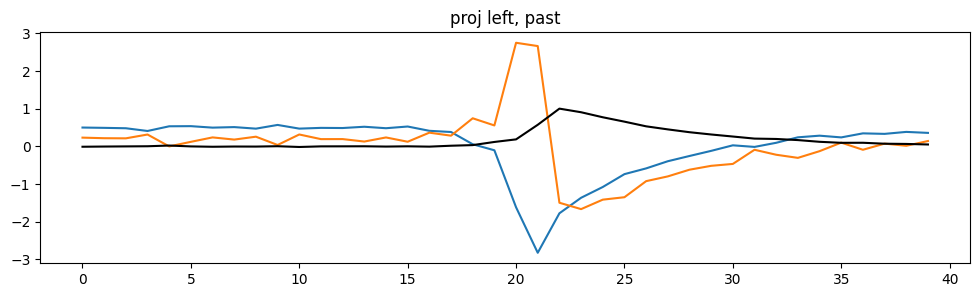

In [614]:
fig = plt.figure(figsize=(12, 3))
plt.plot(proj_left.T[20:60])
plt.plot(X.ravel()[20:60], c="k")
plt.title("proj left, past")

Text(0.5, 1.0, 'proj right, future')

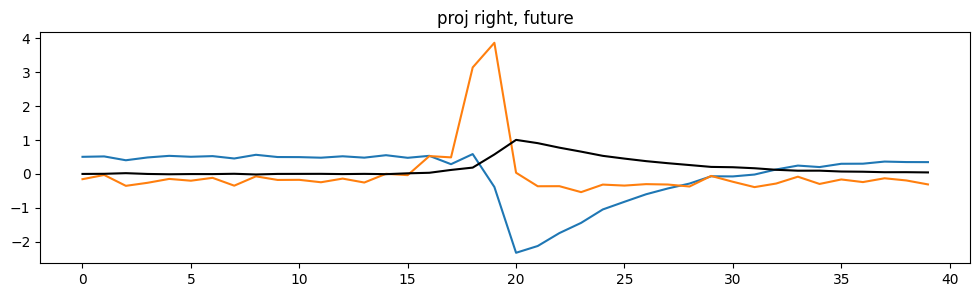

In [617]:
fig = plt.figure(figsize=(12, 3))
plt.plot(proj_right.T[20:60])
plt.plot(X.ravel()[20+lag:60+lag], c="k")
plt.title("proj right, future")

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
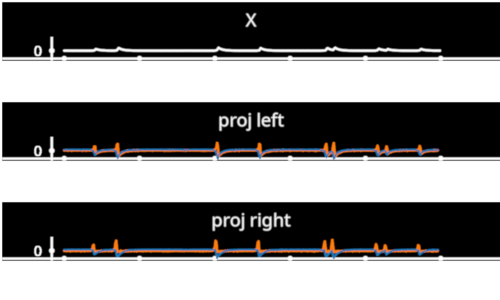

In [358]:
fig2 = fpl.Figure((3, 1), names=[["X", "proj left", "proj right"]], controller_ids="sync")

fig2["X"].add_line(X.ravel())
fig2["proj left"].add_line_collection(proj_left, cmap="tab10")
fig2["proj right"].add_line_collection(proj_right, cmap="tab10")

fig2.show(maintain_aspect=False)

In [635]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler, StandardScaler

In [648]:
km = KMeans(3)

In [649]:
proj_left.shape

(2, 497)

In [650]:
proj_right.shape

(2, 497)

In [651]:
features = np.hstack([proj_left.T[:, :3]])#, proj_right.T[:, :3]])
features.shape

(497, 2)

In [652]:
labels = km.fit_predict(features)

In [653]:
labels.shape

(497,)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
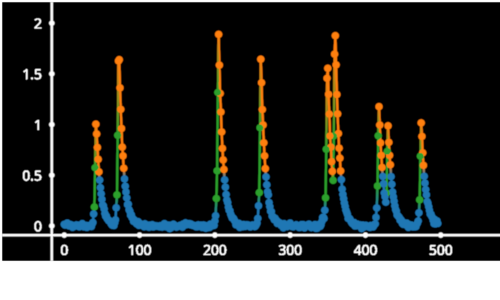

In [654]:
fig3 = fpl.Figure()

fig3[0, 0].add_line(np.column_stack([np.arange(labels.shape[0]), X.ravel()[:-3]]), cmap="tab10", cmap_transform=labels)
fig3[0, 0].add_scatter(np.column_stack([np.arange(labels.shape[0]), X.ravel()[:-3]]), sizes=7, cmap="tab10", cmap_transform=labels)

fig3.show(maintain_aspect=False)

In [370]:
from deeptime.basis import Monomials

In [377]:
Y = Monomials(p=2, d=2)(H[:2].T)

mu0 = np.mean(Y[:-lag,:])
mu1 = np.mean(Y[lag:,:])
Past = Y[:-lag,:]
Future = Y[lag:,:]

# covariance matrices
C00 = (Past - mu0).T@(Past - mu0)/(Past.shape[0] - 1)
C11 = (Future - mu1).T@(Future - mu1)/(Future.shape[0] - 1)
C01 = (Past - mu0).T@(Future - mu1)/(Past.shape[0] - 1)
C00_half = linalg.sqrtm(C00)
C11_half = linalg.sqrtm(C11)

K = np.linalg.pinv(C00)@C01

# half-weighted koopman
Kbar = np.linalg.pinv(C00_half)@C01@np.linalg.pinv(C11_half)
# SVD 
U, S, Vh = np.linalg.svd(Kbar,full_matrices=False)

# mapping data to the left and right sigular vectors
left_vec = np.linalg.pinv(C00_half)@U
right_vec = np.linalg.pinv(C11_half)@Vh.T

# projection of data onto left and right singular vectors
proj_left = left_vec.T @ (Past.T - mu0)
proj_right = right_vec.T @ (Future.T - mu1)

Text(0.5, 1.0, 'right')

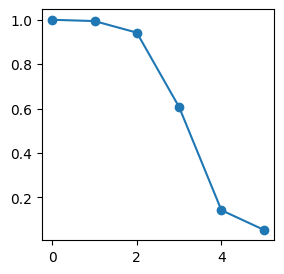

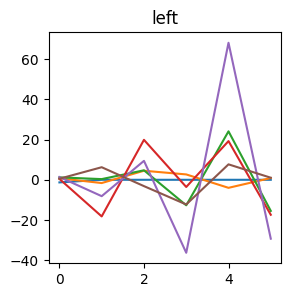

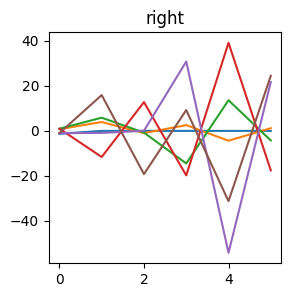

In [378]:
plt.figure(figsize=(3, 3))
plt.plot(S / S.max(),'o-')

plt.figure(figsize=(3, 3))
plt.plot(left_vec)
plt.title("left")

plt.figure(figsize=(3, 3))
plt.plot(right_vec)
plt.title("right")

Text(0.5, 1.0, 'proj left')

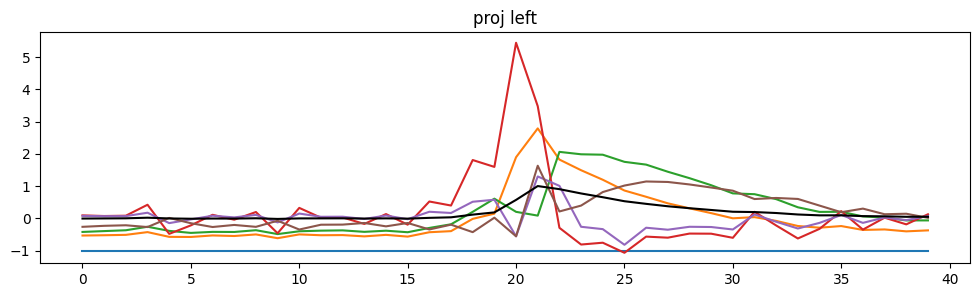

In [380]:
fig = plt.figure(figsize=(12, 3))
plt.plot(proj_left.T[20:60])
plt.plot(X.ravel()[21:61], c="k")
plt.title("proj left")

Text(0.5, 1.0, 'proj right')

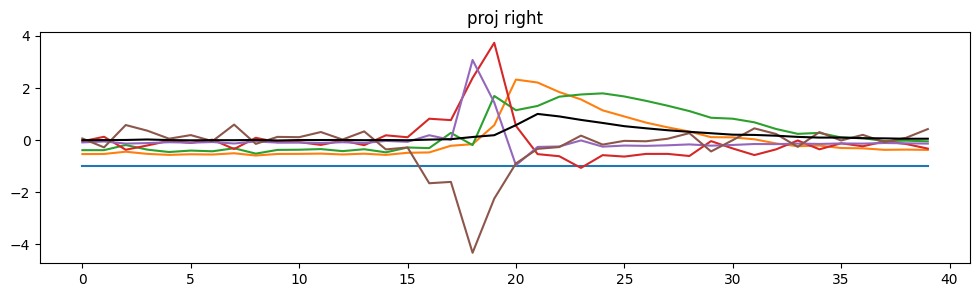

In [381]:
fig = plt.figure(figsize=(12, 3))
plt.plot(proj_right.T[20:60])
plt.plot(X.ravel()[21:61], c="k")
plt.title("proj right")

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
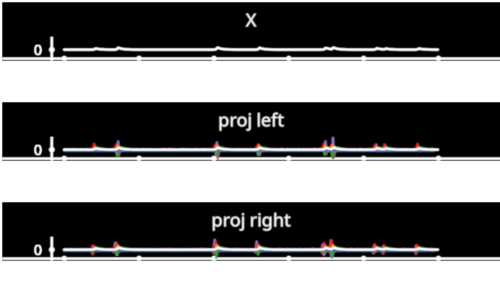

In [383]:
fig2 = fpl.Figure((3, 1), names=[["X", "proj left", "proj right"]], controller_ids="sync")

fig2["X"].add_line(X.ravel())

fig2["proj left"].add_line_collection(proj_left, cmap="tab10", alpha=0.5)
fig2["proj left"].add_line(X.ravel())
fig2["proj right"].add_line_collection(proj_right, cmap="tab10", alpha=0.5)
fig2["proj right"].add_line(X.ravel())

fig2.show(maintain_aspect=False)

In [475]:
from sklearn.cluster import KMeans

In [555]:
km = KMeans(3)

In [556]:
proj_left.shape

(6, 495)

In [557]:
proj_right.shape

(6, 495)

In [559]:
max_k = 4

In [569]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, PowerTransformer

<Axes: >

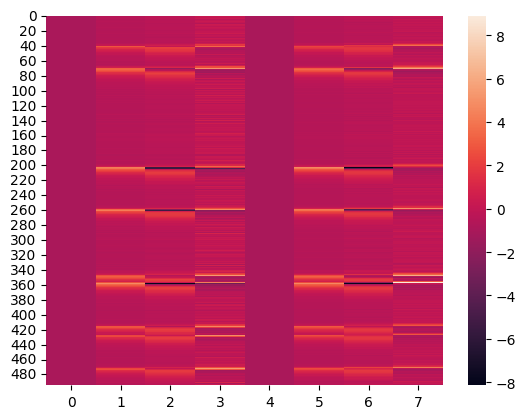

In [570]:
features = np.hstack([proj_left.T[:, :max_k], proj_right.T[:, :max_k]])
sns.heatmap(features)

In [578]:
features = MinMaxScaler().fit_transform(features)
features.shape

(495, 8)

In [579]:
np.ptp(features, axis=0)

array([1., 1., 1., 1., 1., 1., 1., 1.])

In [580]:
features.mean(axis=0)

array([0.02361739, 0.37281481, 0.66852427, 0.70899827, 0.02361739,
       0.38936087, 0.6734464 , 0.69658648])

<Axes: >

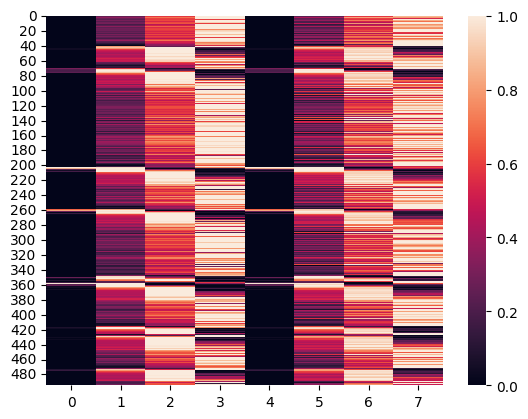

In [581]:
sns.heatmap(features)

In [582]:
labels = km.fit_predict(features)

In [583]:
labels.shape

(495,)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='300.0px', css_width='1000.0px')
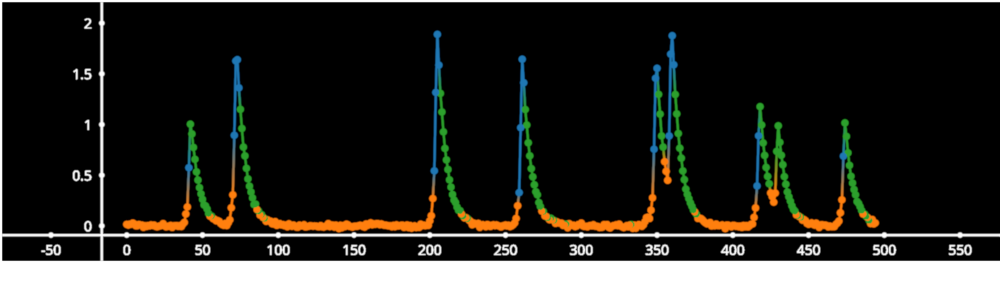

In [584]:
fig3 = fpl.Figure(size=(1000, 300))

fig3[0, 0].add_line(np.column_stack([np.arange(labels.shape[0]), X.ravel()[:-5]]), cmap="tab10", cmap_transform=labels)
fig3[0, 0].add_scatter(np.column_stack([np.arange(labels.shape[0]), X.ravel()[:-5]]), sizes=7, cmap="tab10", cmap_transform=labels)

fig3.show(maintain_aspect=False)